# Error profiles of assigned reads

Assigned Read 1 sequences at $r = 7$ are aligned to the called barcode (Needleman–Wunsch on a subsample). Short-insert assigned reads (adapter inside the barcode window) are counted per count group. Read 1 / Read 2 Hamming distance after reverse-complementing Read 2 is reported for full-length assigned pairs.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})
OUT = Path(".")

import error_profiles as ep

if not (OUT / "error_profiles_by_group.csv").exists():
    ep.main()
prof = pd.read_csv(OUT / "error_profiles_by_group.csv")
pos = pd.read_csv(OUT / "positional_errors.csv")
conc = pd.read_csv(OUT / "r1_r2_concordance.csv")
display(prof.round(3))
display(conc.round(3))

,layout,group,assigned_reads,short_insert_frac,mean_substitutions,mean_insertions,mean_deletions
0,Dual barcodes,low,15796,0.017,2.126,2.619,2.619
1,Dual barcodes,medium,72199,0.017,2.129,2.578,2.578
2,Dual barcodes,high,88617,0.019,2.080,2.548,2.548
3,Greedy + 2-OPT,low,21964,0.004,1.766,3.711,3.711
4,Greedy + 2-OPT,medium,37852,0.003,1.684,3.678,3.678
5,Greedy + 2-OPT,high,6510,0.020,1.748,3.471,3.471
6,Zipcodes,low,17932,0.006,1.838,3.362,3.362
7,Zipcodes,medium,73195,0.009,1.796,3.321,3.321
8,Zipcodes,high,88473,0.010,1.738,3.257,3.257


,layout,n_pairs,median_r1_r2_hamming,frac_hamming_le3,frac_hamming_le6
0,Dual barcodes,20000,0.0,0.589,0.590
1,Greedy + 2-OPT,20000,0.0,0.793,0.794
2,Zipcodes,20000,0.0,0.684,0.685


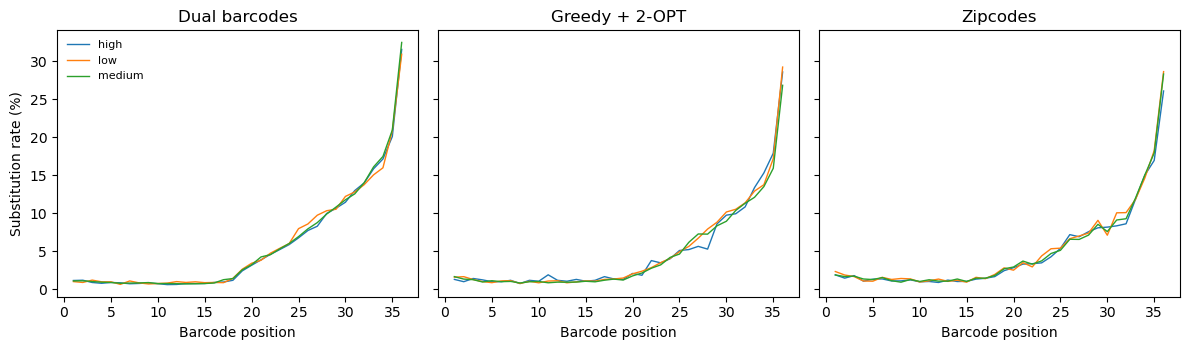

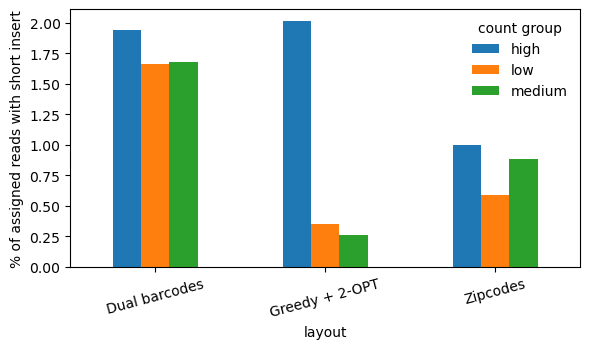

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (name, d) in zip(axes, pos.groupby("layout")):
    for g, gd in d.groupby("group"):
        if g == "zero" or gd.n.max() < 50:
            continue
        ax.plot(gd.position, gd.substitution_rate * 100, lw=1, label=g)
    ax.set_title(name)
    ax.set_xlabel("Barcode position")
axes[0].set_ylabel("Substitution rate (%)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "positional_substitutions.pdf")
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.6))
wide = prof.pivot(index="layout", columns="group", values="short_insert_frac") * 100
wide.plot(kind="bar", ax=ax, rot=15)
ax.set_ylabel("% of assigned reads with short insert")
ax.legend(frameon=False, title="count group")
fig.tight_layout()
fig.savefig(OUT / "short_insert_by_group.pdf")
plt.show()